# V54 — Validación externa con un solo escalamiento (6 materiales)

Igual que V49, salvo el traslado al dominio: **todas** las curvas usan su ventana diástole–sístole y conservan sus propias tensiones.
- **M (in vivo, medida):** Liu et al. 2012 y Kamenskiy et al. 2012, como en V49.
- **P (ex vivo, calculada):** Sommer y Holzapfel 2012. El estiramiento a 60 y a 200 mmHg (la misma ventana de presión del nivel tubo) sale del equilibrio de pared delgada de Sommer et al. (2010, ec. 1–2) con la geometría sin carga de su Tabla 2.
- Se excluye Holzapfel et al. 2000 (conejo): como capas aisladas dan tensiones de 900 a 3300 kPa.
- Se elimina el protocolo T (ventana por tensión), que fijaba las tensiones de los extremos a las de la población de Masson.


# V49 — 6 bases: el método de nivel σ frente a mediciones documentadas de otros autores
Celdas 0–11: las de V39 (ley de Masson, espacio de trabajo, bases, red de V35 que se **carga**, sin reentrenar). Celda 24: solo las funciones de redondeo. Celdas V49-1 a V49-4: curvas externas (Sommer y Holzapfel 2012, Holzapfel et al. 2000, Liu et al. 2012, Kamenskiy et al. 2012), evaluación y figuras.

Archivos necesarios en la carpeta: tabla2_masson_NT.csv, tabla4_masson_HT.csv, bases_v39_6.csv, modelo_rn_curva_j_v35_6.keras, scalers_curva_j_v35_6.pkl, historial_entrenamiento_v35_6.csv.

In [1]:
# CELDA 0: CONFIGURACIÓN (ejecutar siempre primero)
import os
import numpy as np

N_BASES = 6                      # ← número de bases (materiales): 4, 5 o 6. Cada número de bases tiene su propia red
VERSION = f"v49_{N_BASES}"
SEED = 42
DIR_MASSON = "."                 # tablas de Masson en la misma carpeta que el notebook
ENTRENAR = "auto"                # "auto": carga la red si sus archivos están en la carpeta y, si no, la entrena;
                                 # True: entrena siempre; False: carga siempre (error si faltan los archivos)
# ENSAYOS DE LOS MATERIALES: un solo CSV con la columna lambda (estiramiento circunferencial del injerto, el mismo λθ de las curvas,
#   con el montaje y el rizado de las fibras ya incluidos) y una columna material_j por cada material ensayado (tensión de Cauchy
#   [MPa]). Los materiales sin columna (o con la columna vacía) siguen con su base ideal (recta truncada: fibra como hilo).
#   Con ensayos, la red se REENTRENA (Celda 11, ≈ 40–60 min). Formato: ver plantilla_ensayos_v39_N.csv.
ARCHIVO_ENSAYOS = f"ensayos_v39_{N_BASES}.csv"   # si el archivo no está en la carpeta: bases ideales
GUARDAR_PLANTILLA_ENSAYO = True  # True: la Celda 3 escribe plantilla_ensayos_v39_N.csv (las bases ideales en el formato del ensayo)
ENSAYOS = []                     # materiales ensayados (se detectan solos)
if os.path.exists(ARCHIVO_ENSAYOS):
    import pandas as pd
    _e = pd.read_csv(ARCHIVO_ENSAYOS)
    ENSAYOS = [j for j in range(1, N_BASES + 1) if f"material_{j}" in _e and _e[f"material_{j}"].notna().sum() >= 2]
# Red: con bases ideales se usa la red de V35 (mismas bases); con ensayos, una red propia que se entrena la primera vez.
MODELO_RED = f"v35_{N_BASES}" if not ENSAYOS else f"{VERSION}_ensayos_" + "_".join(map(str, ENSAYOS))
if ENTRENAR == "auto":
    ENTRENAR = not os.path.exists(f"modelo_rn_curva_j_{MODELO_RED}.keras")

# V35: las curvas son TENSIONES σθθ(λθ) en r_m (ley de Masson), no presiones. Cada base = UNA lámina de un material:
#   A_j(λ) = S_j·max(0, λ − k_j)   (recta truncada), con S_j = PEND_MAX_j / C_LAM_j.
#   Nudos k_j y pendientes S_j se ajustan desde cero a las curvas de σ (Celda 3).
ARCHIVO_BASES = f"bases_v39_{N_BASES}.csv"   # mismos nudos que V39   # nudos y pendientes de las bases: la Celda 3 los lee de acá; si no existe, busca los
                                             # nudos (≈ 25 min) y lo escribe (columnas material, nudo, pendiente_lamina_kPa)
OPTIMIZAR_NUDOS = False          # True: vuelve a buscar los nudos (y sobrescribe ARCHIVO_BASES) aunque el archivo exista
NUDOS_FORZADOS = None            # opcional: una lista de N_BASES nudos para imponerlos a mano (ignora el archivo)
UMBRAL_COND = 30.0               # cota de cond(A) (columnas normalizadas) que deben cumplir los nudos
PESO_NEG = 10.0                  # peso de la penalización por láminas negativas del MCO libre al elegir los nudos (evaluada en todo el espacio)
SIGNO_ESTRICTO = True            # True: la Celda 3 exige 0 curvas del espacio de trabajo con láminas < −TOL_NEG
SEP_MIN_NUDOS = 0.008            # separación mínima entre nudos
MARGEN_NUDO_FINAL = 0.012        # el último nudo queda ≥ 0,012 antes de X_MAX: si no, su material actúa en muy pocos puntos y la red no lo distingue
TOL_NEG = 0.01                   # lámina negativa tolerada (en láminas de la red, de 10): 0,1 % del máximo
C_LAM = 20                       # máximo de láminas por material (configuración adoptada: 20) (solo para las Celdas 3 a 22): un número para todos o una lista de N_BASES valores; no requiere reentrenar
C_LAM_RED = 10.0                 # láminas con que se entrena la red (no cambiar)

ERROR_MAX_PCT = 3.0              # criterio: error punto a punto ≤ 3 % del rango de la curva
SUJETO_Y1, SUJETO_Y2 = "NT16", "HT09"                            # sujetos de partida de las curvas límite
# y1: ley de Masson con la geometría y las fibras de NT16 y estos 5 parámetros (dentro del rango de los 41 sujetos),
#     elegidos para que y1(X_MIN) = mín. de los 41 sujetos en X_MIN (HT10, 4,71 kPa) y y1 ≤ los 41 sujetos en todo el dominio
PARAM_Y1 = {"c_kPa": 43.6135, "c1_kPa": 5.0302, "c1circ_kPa": 5.1034, "c2circ": 11.8183, "Tm_kPa": 22.3336}
LAMBDA_Y2, Y2_MAX = 1.10, 300.0  # y2 = HT09 hasta LAMBDA_Y2 y luego llega a Y2_MAX [kPa] en X_MAX (≥ los 41 sujetos)
X_MIN, X_MAX, N_PTS = 1.02, 1.16, 999
X = np.linspace(X_MIN, X_MAX, N_PTS)
FRAC_SUJETOS_TEST = 0.25
X_INICIO_CONVEXIDAD, TOL_FORMA_REL = 1.05, 0.01                  # control de forma J
TOL_CLASE_NRMSE, N_NUDOS_CLASE, NUDO_MIN_CLASE = 2.0, 40, 0.85   # control de clase a la entrada
ETQ_X, ETQ_Y = r"$\lambda_\theta$ (en $r_m$)", r"$\sigma_{\theta\theta}$ en $r_m$ [kPa]"
ETQ_YN = r"$(\sigma - \sigma_{mín})/\Delta\sigma$"     # forma adimensional: 0 en λ = X_MIN, 1 en λ = X_MAX

_v = MODELO_RED
ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL = (f"modelo_rn_curva_j_{_v}.keras", f"scalers_curva_j_{_v}.pkl",
                                                      f"historial_entrenamiento_{_v}.csv")
print(f"✅ {VERSION} | curvas σθθ(λθ) en r_m | λθ ∈ [{X_MIN}, {X_MAX}] | {N_BASES} bases "
      f"({'ideales' if not ENSAYOS else 'ensayos de los materiales ' + str(ENSAYOS)}) | "
      f"red: {'se entrena → ' if ENTRENAR else 'se carga de '}{ARCHIVO_MODELO}")


✅ v49_6 | curvas σθθ(λθ) en r_m | λθ ∈ [1.02, 1.16] | 6 bases (ideales) | red: se carga de modelo_rn_curva_j_v35_6.keras


In [2]:
# CELDA 1: MODELO DE MASSON ET AL. (2011) Y CURVAS σθθ(λθ) DE LOS 41 SUJETOS
# σθθ: tensión circunferencial de Cauchy en r_m (borde media–adventicia), como en las Figs. 5a y 7a de Masson.
# Sale directo de la ley de Masson con los parámetros de las Tablas 2 y 4: no hace falta suponer el espesor de la pared.
import os
import numpy as np
import pandas as pd

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def sigma_masson(lt, p, restar_Pa=True):
    """σθθ(λθ) [kPa] en r_m: elastina neo-Hookeana + 4 familias de colágeno + tono activo."""
    lt = np.asarray(lt, float)
    lz, al = p["lambda_ax"], np.deg2rad(p["alpha_deg"])
    lam_d = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    suma = np.zeros_like(lt)
    for lam_k, c1, c2, ang in [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0), (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),
                               (lam_d, p["c1_kPa"], p["c2"], al), (lam_d, p["c1_kPa"], p["c2"], -al)]:
        E = lam_k ** 2 - 1.0
        suma = suma + c1 * E * np.exp(c2 * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    s = -p["c_kPa"] * (1.0 / (lt * lz)) ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo
    return s - p["a_kPa"] * np.exp(p["b"]) if restar_Pa else s


def curva_objetivo(lt_m, p):
    """σθθ(λθ) en r_m [kPa] (ley de Masson, con la presión perivascular P_a restada como en el paper)."""
    return sigma_masson(np.asarray(lt_m, float), p, restar_Pa=True)


def diagnostico_forma(y, x=X):
    """(monótona, convexa desde X_INICIO_CONVEXIDAD), con tolerancia relativa a la pendiente máxima."""
    p = np.diff(y) / np.diff(x)
    tol = TOL_FORMA_REL * max(float(np.abs(p).max()), 1e-9)
    return bool(p.min() >= -tol), bool(np.diff(p)[x[1:-1] >= X_INICIO_CONVEXIDAD].min() >= -tol)


POB = pd.concat([pd.read_csv(f"{DIR_MASSON}/{f}").assign(grupo=g) for f, g in
                 [("tabla2_masson_NT.csv", "NT"), ("tabla4_masson_HT.csv", "HT")]], ignore_index=True)
POB["id"] = POB["grupo"] + POB["subject"].map("{:02d}".format)
POB_Y = np.array([curva_objetivo(X, r) for _, r in POB.iterrows()])

# Sujetos reservados para test (estratificado por grupo): no entran al generador
_rng = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    i_g = POB.index[POB["grupo"] == g].to_numpy()
    POB.loc[_rng.choice(i_g, size=int(round(FRAC_SUJETOS_TEST * len(i_g))), replace=False), "test"] = True
MASK_TEST = POB["test"].to_numpy()
MASK_TRAIN = ~MASK_TEST

# Curvas límite: y1 = ley de Masson (geometría de NT16 con PARAM_Y1), por debajo de los 41 sujetos y con y1(X_MIN) = mín. medido;
# y2 = HT09 + a·(exp(b·E²) − 1), E = (λ/LAMBDA_Y2)² − 1 > 0, con b = c2circ de HT09 y a tal que y2(X_MAX) = Y2_MAX
_p1 = POB.loc[POB["id"] == SUJETO_Y1].iloc[0].copy()
for _k, _v in PARAM_Y1.items():
    _p1[_k] = _v
Y1 = curva_objetivo(X, _p1)
_y2 = POB_Y[(POB["id"] == SUJETO_Y2).to_numpy()][0]
_g = np.exp(float(POB.loc[POB["id"] == SUJETO_Y2, "c2circ"].iloc[0]) * np.maximum(0.0, (X / LAMBDA_Y2) ** 2 - 1.0) ** 2) - 1.0
Y2 = _y2 + (Y2_MAX - _y2[-1]) / _g[-1] * _g
_i0 = int(POB_Y[:, 0].argmin())
assert abs(Y1[0] - POB_Y[_i0, 0]) < 1e-3, "y1(X_MIN) debe ser la menor tensión medida en X_MIN"
assert np.all(Y1 <= POB_Y.min(axis=0) + 1e-6), "y1 debe quedar por debajo de los 41 sujetos"
assert all(diagnostico_forma(Y1)), "y1 debe tener forma J"
ETQ_BANDA = f"Curvas límite y1 (Masson, y1({X_MIN}) = {Y1[0]:.2f} kPa = {POB.id[_i0]}) – y2 ({SUJETO_Y2} → {Y2_MAX:g} kPa)"
print(f"y1: ley de Masson, y1({X_MIN}) = {Y1[0]:.3f} kPa (= {POB.id[_i0]}), y1({X_MAX}) = {Y1[-1]:.2f} kPa; "
      f"distancia mínima a los 41 sujetos fuera de X_MIN: {(POB_Y.min(axis=0) - Y1)[1:].min():.4f} kPa")


def dentro_espacio(Y, tol=1e-9):
    Y = np.atleast_2d(Y)
    return np.all((Y >= Y1 - tol) & (Y <= Y2 + tol), axis=1)


def banda(ax, x=X):
    ax.fill_between(x, np.interp(x, X, Y1), np.interp(x, X, Y2), color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)


GRUPOS_MEDIAS = {"Mean Young": (POB["grupo"] == "NT") & (POB["age"] <= 42), "Mean Old": (POB["grupo"] == "NT") & (POB["age"] >= 53),
                 "Mean NT": (POB["grupo"] == "NT") & (POB["age"] >= 39), "Mean HT": POB["grupo"] == "HT"}
MEDIAS = {k: POB_Y[m.to_numpy()].mean(axis=0) for k, m in GRUPOS_MEDIAS.items()}

_dent = dentro_espacio(POB_Y)
print(f"✅ {len(POB)} sujetos ({(POB.grupo == 'NT').sum()} NT, {(POB.grupo == 'HT').sum()} HT) | test: {', '.join(POB.id[MASK_TEST])}")
print(f"   σθθ en λ = {X_MIN}: [{POB_Y[:, 0].min():.1f}, {POB_Y[:, 0].max():.1f}] kPa | en λ = {X_MAX}: "
      f"[{POB_Y[:, -1].min():.1f}, {POB_Y[:, -1].max():.1f}] kPa | forma J (monótona y convexa): "
      f"{np.mean([all(diagnostico_forma(y)) for y in POB_Y]):.0%}")
print(f"   Dentro de y1–y2 en todo el dominio: {_dent.sum()}/{len(POB)} | fuera: {', '.join(POB.id[~_dent])}")

# Validación contra las medias de σθθ digitalizadas del paper (Figs. 5a y 7a)
if os.path.exists(f"{DIR_MASSON}/masson2011_curvas_medias.csv"):
    dig = pd.read_csv(f"{DIR_MASSON}/masson2011_curvas_medias.csv")
    for k, m in GRUPOS_MEDIAS.items():
        d = dig[dig.curva == k]
        s = np.mean([sigma_masson(d.lambda_theta.to_numpy(), r) for _, r in POB[m].iterrows()], axis=0)
        e = np.sqrt(np.mean((s - d.sigma_theta_kPa.to_numpy()) ** 2))
        print(f"   σθθ reconstruida vs. paper, {k:<10} (n = {m.sum():>2}): RMSE {e:.2f} kPa ({e / d.sigma_theta_kPa.mean():.1%})")
pd.DataFrame(POB_Y.T, index=pd.Index(np.round(X, 6), name="lambda_theta"), columns=POB["id"]).to_csv(
    f"curvas_tension_poblacion_{VERSION}.csv")


y1: ley de Masson, y1(1.02) = 4.712 kPa (= HT10), y1(1.16) = 53.48 kPa; distancia mínima a los 41 sujetos fuera de X_MIN: 0.0000 kPa
✅ 41 sujetos (16 NT, 25 HT) | test: NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24
   σθθ en λ = 1.02: [4.7, 49.3] kPa | en λ = 1.16: [53.9, 289.8] kPa | forma J (monótona y convexa): 100%
   Dentro de y1–y2 en todo el dominio: 41/41 | fuera: 


In [3]:
# CELDA 2: ESPACIO DE TRABAJO — CURVAS FISIOLÓGICAS SINTÉTICAS (no dependen de las bases)
#   2 constitutiva / 3 amplia / 5 uniforme: ley de Masson dentro de y1–y2   4 exponencial: otra ley   6 pacientes de entrenamiento
#   Con las familias 2, 3 y 5 (el espacio de trabajo) la Celda 3 calcula las pendientes máximas y, si hace falta, los nudos.
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

N_SAMPLES = 50000
FRAC = {0: 0.20, 1: 0.20, 2: 0.20, 4: 0.10, 6: 0.05, 5: 0.10}      # la amplia (3) completa el total
FAMILIAS = {0: "pura", 1: "combinada", 2: "constitutiva", 3: "constitutiva_amplia", 4: "exponencial",
            5: "constitutiva_uniforme", 6: "pacientes"}
FAMILIAS_OBJETIVO = (2, 3, 4, 5, 6)
Y_TECHO, RUIDO_CONST = 1.5 * float(POB_Y.max()), 0.01
PERTURB = {2: dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, amp=(0.85, 1.20), gamma=(1.0, 1.0)),
           3: dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, amp=(0.65, 1.50), gamma=(1.0, 1.35)),
           4: dict(k=(2, 3), sd_log=0.15, amp=(0.70, 1.40))}
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa"]          # perturbación log-normal
PARAM_ADIT = ["Theta0_deg", "lambda_ax", "c2", "c2circ", "alpha_deg", "lambda0", "lambda_m", "b"]   # en desvíos poblacionales
rng = np.random.default_rng(2026)
N_FAM = {f: int(round(v * N_SAMPLES)) for f, v in FRAC.items()}
N_FAM[3] = N_SAMPLES - sum(N_FAM.values())
ruido = lambda Y, r, g: np.maximum(Y + g.normal(0.0, r, size=Y.shape) * np.abs(Y), 0.0)
LIMPIAS, RUIDOSAS, ACEPTACION = {}, {}, {}

# C) leyes constitutivas: mezcla convexa (Dirichlet) de sujetos de entrenamiento + perturbación + amplitud
TH = POB.loc[MASK_TRAIN, COLS_PARAM].to_numpy(float)
SD = POB[COLS_PARAM].to_numpy(float).std(axis=0)
ix = {c: i for i, c in enumerate(COLS_PARAM)}
iM, iA = [ix[c] for c in PARAM_MULT], [ix[c] for c in PARAM_ADIT]
es_mult = np.isin(np.arange(len(COLS_PARAM)), iM)
a_z = lambda t: np.where(es_mult, np.log(np.maximum(t, 1e-9)), t)       # módulos en escala log
de_z = lambda z: np.where(es_mult, np.exp(np.where(es_mult, z, 0.0)), z)
Z = a_z(TH)
amplitud = lambda cfg: float(np.exp(rng.uniform(np.log(cfg["amp"][0]), np.log(cfg["amp"][1]))))


def ley_exp(x, C, mu, k1, k2):
    E = x ** 2 - 1.0
    return C + mu * E + k1 * E * np.exp(k2 * E ** 2)


def valida(y, acotar=True):
    return (np.all(np.isfinite(y)) and y.min() > 0 and y.max() <= Y_TECHO and all(diagnostico_forma(y))
            and (not acotar or bool(dentro_espacio(y)[0])))


def masson(th):
    return None if th[ix["lambda_m"]] <= th[ix["lambda0"]] + 0.2 else curva_objetivo(X, dict(zip(COLS_PARAM, th)))


def sortear(f):
    """Una curva de la familia f, o None si se rechaza."""
    if f == 5:                                                      # uniforme: parámetros independientes en [mín, máx]
        y = masson(de_z(rng.uniform(a_z(TH.min(0)), a_z(TH.max(0)))))
        return y if y is not None and valida(y) else None
    cfg = PERTURB[f]
    k = rng.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng.choice(len(TH), size=k, replace=False)
    w = rng.dirichlet(np.ones(k))
    if f == 4:                                                      # exponencial: media geométrica de ajustes
        p = np.exp(w @ np.log(P_EXP[idx]) + rng.normal(0.0, cfg["sd_log"], size=4))
        y = amplitud(cfg) * ley_exp(X, *p)
        return y if valida(y, acotar=False) else None
    z = Z.mean(0) + rng.uniform(*cfg["gamma"]) * (w @ Z[idx] - Z.mean(0))     # γ > 1: extrapola desde el centro
    z[iM] += rng.normal(0.0, cfg["sd_mult"], size=len(iM))
    z[iA] += rng.normal(0.0, cfg["sd_adit"], size=len(iA)) * SD[iA]
    th = de_z(z)
    th[ix["alpha_deg"]] = np.clip(th[ix["alpha_deg"]], 5.0, 85.0)
    th[ix["lambda_ax"]] = max(th[ix["lambda_ax"]], 1.0)
    th[[ix["c2"], ix["c2circ"]]] = np.maximum(th[[ix["c2"], ix["c2circ"]]], 0.5)
    th[ix["Theta0_deg"]] = np.clip(th[ix["Theta0_deg"]], 60.0, 300.0)
    y = masson(th)
    if y is None:
        return None
    y = amplitud(cfg) * y
    return y if valida(y) else None


P_EXP = np.maximum([curve_fit(ley_exp, X, y, p0=(max(y[0] - 5.0, 1.0), 50.0, 20.0, 10.0), maxfev=40000,
                              bounds=([0, 0, 1e-3, 1e-3], [1e3, 2e3, 2e3, 200.0]))[0] for y in POB_Y[MASK_TRAIN]], 1e-3)
for f in (2, 3, 4, 5):
    Y, intentos = [], 0
    while len(Y) < N_FAM[f]:
        y, intentos = sortear(f), intentos + 1
        if y is not None:
            Y.append(y)
    LIMPIAS[f], ACEPTACION[f] = np.array(Y), N_FAM[f] / intentos
    RUIDOSAS[f] = ruido(LIMPIAS[f], RUIDO_CONST, rng)
LIMPIAS[6] = POB_Y[MASK_TRAIN][np.resize(np.arange(MASK_TRAIN.sum()), N_FAM[6])]       # pacientes reales (sin recorte en 0)
RUIDOSAS[6] = LIMPIAS[6] + rng.normal(0.0, RUIDO_CONST, size=LIMPIAS[6].shape) * np.abs(LIMPIAS[6])

W_ESP = np.vstack([LIMPIAS[f] for f in (2, 3, 5)])                         # espacio de trabajo (curvas de Masson en y1–y2)
print(f"✅ Espacio de trabajo: {len(W_ESP)} curvas de Masson dentro de y1–y2 | aceptación: "
      + ", ".join(f"{FAMILIAS[f]} {100 * ACEPTACION[f]:.1f}%" for f in (2, 3, 4, 5)) + f" | σθθ en λ = {X_MAX}: "
      f"p1 {np.percentile(W_ESP[:, -1], 1):.1f} | p50 {np.median(W_ESP[:, -1]):.1f} | máx. {W_ESP[:, -1].max():.1f} kPa")


✅ Espacio de trabajo: 22500 curvas de Masson dentro de y1–y2 | aceptación: constitutiva 97.9%, constitutiva_amplia 88.8%, exponencial 99.7%, constitutiva_uniforme 98.3% | σθθ en λ = 1.16: p1 62.1 | p50 131.1 | máx. 299.9 kPa


In [4]:
# CELDA 3: BASES = UNA LÁMINA DE CADA MATERIAL, A_j(λ) = S_j·max(0, λ − k_j), S_j = PEND_MAX_j / C_LAM_j
#   Nudos y pendientes se ajustan desde cero a las curvas de σθθ. (Se probó la forma λ²·max(0, λ − k): el MCO ajusta igual,
#   pero la red aprende 2 veces peor; por eso se usan rectas truncadas.)
# 1) Nudos: se leen de ARCHIVO_BASES (Celda 0). Si el archivo no existe, si OPTIMIZAR_NUDOS = True o si no cumplen cond(A) < UMBRAL_COND,
#    se buscan y se GUARDAN en ese archivo (no hay que copiar nada a la Celda 0). Búsqueda: minimax (media del peor 1 % del error punto a punto del MCO en el espacio de trabajo) con cond(A) < UMBRAL_COND
#    y penalización PESO_NEG por láminas negativas del MCO libre en TODO el espacio de trabajo (la base se elige para que el
#    ajuste sin condiciones dé c ≥ 0; las pendientes no cambian el signo: solo escalan cada columna).
#    Búsqueda: evolución diferencial (global, sin derivadas) y refinamiento final con Nelder–Mead.
# 2) PEND_MAX = máxima pendiente que exige el espacio de trabajo a cada capa (MCO con líneas sin escalar).
# Cambiar C_LAM solo cambia la rigidez de cada lámina, no el ajuste: c_j (diseño) = c_j (red) · C_LAM_j / C_LAM_RED.
import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution, minimize


FORMA_ENSAYO = {}                                     # material (0 a N−1) → forma medida (se llena abajo si hay ENSAYOS)


def forma_base(lam, k):
    """Forma de cada base (una columna por nudo): recta truncada max(0, λ − k) o, si el material tiene ensayo, su curva medida."""
    lam = np.asarray(lam, float)[:, None]
    F = np.maximum(0.0, lam - np.asarray(k, float))
    for j, f in FORMA_ENSAYO.items():
        F[:, j] = f(lam[:, 0])
    return F


def leer_ensayo(archivo, j):
    """σ [kPa] del material j según el CSV de ensayos (columnas lambda y material_j): interpolación lineal, 0 antes del primer
    punto medido y recta con la última pendiente después del último."""
    d = pd.read_csv(archivo)[["lambda", f"material_{j}"]].dropna().sort_values("lambda")
    le, se = d["lambda"].to_numpy(float), d[f"material_{j}"].to_numpy(float) * 1e3
    m = (se[-1] - se[-2]) / (le[-1] - le[-2])
    return lambda l: np.where(np.asarray(l) <= le[-1], np.interp(l, le, se, left=0.0), se[-1] + m * (np.asarray(l) - le[-1]))


def lineas(k, x=X):
    return forma_base(x, np.sort(np.asarray(k, float)))


def cond_A(k):
    s = np.linalg.svd(lineas(k) / lineas(k).max(axis=0), compute_uv=False)
    return s[0] / s[-1]


def optimizar_nudos(n_b):
    """Nudos minimax para n_b bases: cond(A) < UMBRAL_COND y láminas ≥ 0 (evolución diferencial + refinamiento Nelder–Mead)."""
    W = np.vstack([W_ESP[np.random.default_rng(1).choice(len(W_ESP), min(2500, len(W_ESP)), replace=False)],
                   POB_Y[MASK_TRAIN & dentro_espacio(POB_Y)], Y2])[:, ::2]     # solo datos de entrenamiento
    xs, rg = X[::2], np.ptp(W, axis=1)
    WN = np.vstack([W_ESP, POB_Y[MASK_TRAIN], Y1, Y2])             # signo: todo el espacio + sujetos de entrenamiento + curvas límite (999 puntos)

    def obj(k):
        k = np.sort(k)
        if np.diff(k).min() < SEP_MIN_NUDOS or k[-1] > X_MAX - MARGEN_NUDO_FINAL or k[0] < 0.6:
            return 1e9                                           # fuera de las restricciones: peor que cualquier punto permitido
        G_ = lineas(k, xs)
        Pk = np.linalg.pinv(G_)
        C = Pk @ W.T                                                   # pendientes de cada capa [kPa], una columna por curva
        R = W.T - G_ @ C
        e = np.sort(np.abs(R).max(axis=0) / rg * 100)
        CN = np.linalg.pinv(lineas(k)) @ WN.T
        lam = C_LAM_RED * CN / np.maximum(CN.max(axis=1, keepdims=True), 1e-9)   # láminas (escala de la red)
        return e[-len(e) // 100:].mean() + 0.25 * np.mean(np.sqrt(np.mean(R ** 2, axis=0)) / rg * 100) \
            + 50.0 * max(0.0, cond_A(k) - (UMBRAL_COND - 1.0)) + PESO_NEG * 100 * (neg := np.maximum(0.0, -lam).sum(axis=0)).mean() \
            + (100.0 * neg.max() if SIGNO_ESTRICTO else 0.0)            # estricto: castiga la curva más negativa
    rango = [(0.6, 0.98)] + [(1.0, X_MAX - MARGEN_NUDO_FINAL)] * (n_b - 1)   # k_1 antes del dominio; los demás dentro
    r = differential_evolution(obj, rango, seed=SEED, tol=1e-6, maxiter=300, polish=False)
    r = minimize(obj, r.x, method="Nelder-Mead", options=dict(maxiter=6000, xatol=1e-5, fatol=1e-6))
    return np.round(np.sort(r.x), 4)


def n_negativas(k):
    """Curvas del espacio de trabajo y sujetos con alguna lámina MCO < 0 (el signo no depende de las pendientes)."""
    P_ = np.linalg.pinv(lineas(k))
    return int(((P_ @ W_ESP.T) < 0).any(axis=0).sum()), int(((P_ @ POB_Y.T) < 0).any(axis=0).sum())


_nuevos = False
if NUDOS_FORZADOS is not None:
    NUDOS, _origen = np.sort(np.asarray(NUDOS_FORZADOS, float)), "NUDOS_FORZADOS (Celda 0)"
elif os.path.exists(ARCHIVO_BASES):
    NUDOS, _origen = pd.read_csv(ARCHIVO_BASES).sort_values("material")["nudo"].to_numpy(float), f"'{ARCHIVO_BASES}'"
else:
    NUDOS, _origen = np.array([]), "ninguno"
COND = cond_A(NUDOS) if len(NUDOS) == N_BASES else np.inf
if NUDOS_FORZADOS is None and (OPTIMIZAR_NUDOS or COND >= UMBRAL_COND or len(NUDOS) != N_BASES):
    assert not ENSAYOS, f"con ensayos hacen falta los nudos con que se entrenó la red: copiá su archivo {ARCHIVO_BASES} a esta carpeta"
    print(f"⚙️  Buscando {N_BASES} nudos (origen: {_origen}; cond(A) = {COND:.1f}, umbral {UMBRAL_COND:g}). "
          "Evolución diferencial + Nelder–Mead: ≈ 25 min...")
    NUDOS = optimizar_nudos(N_BASES)
    COND = cond_A(NUDOS)
    _nuevos = True
    _origen = f"búsqueda nueva → se guardan en '{ARCHIVO_BASES}'"
assert len(NUDOS) == N_BASES, f"hacen falta {N_BASES} nudos"
print(f"Nudos ({_origen}): {NUDOS.tolist()}")
# Ensayos: la forma medida se escala para que en X_MAX valga lo mismo que la recta ideal (así una «lámina» conserva su tamaño);
#   lo que cambia es la FORMA de la curva entre 1,02 y 1,16.
_desvio = {}
for jm in ENSAYOS:
    j = jm - 1
    _f = leer_ensayo(ARCHIVO_ENSAYOS, jm)
    _le = pd.read_csv(ARCHIVO_ENSAYOS)[["lambda", f"material_{jm}"]].dropna()["lambda"]
    if _le.min() > X_MIN or _le.max() < X_MAX:
        print(f"⚠️  El ensayo del material {jm} ({ARCHIVO_ENSAYOS}) cubre λ de {_le.min():g} a {_le.max():g}: el rango de la red es "
              f"{X_MIN:g}–{X_MAX:g}. Fuera de lo medido la base se completa con 0 (abajo) o con una recta (arriba): conviene medir todo el rango.")
    _esc = (X_MAX - NUDOS[j]) / max(float(_f(np.array([X_MAX]))[0]), 1e-12)
    FORMA_ENSAYO[j] = (lambda f, e: (lambda l: f(l) * e))(_f, _esc)
    _r, _i = FORMA_ENSAYO[j](X), np.maximum(0.0, X - NUDOS[j])
    _desvio[j + 1] = 100 * np.sqrt(np.mean((_r - _i) ** 2)) / max(np.ptp(_i), 1e-12)
if ENSAYOS:
    COND = cond_A(NUDOS)
    print("Bases con ensayo (forma medida vs. recta ideal, desvío RMS en % del rango de la recta, entre X_MIN y X_MAX): "
          + ", ".join(f"material {j}: {e:.1f} %" for j, e in _desvio.items()))
assert COND < UMBRAL_COND, f"cond(A) = {COND:.1f} ≥ {UMBRAL_COND:g}: subí UMBRAL_COND o bajá N_BASES"
G = lineas(NUDOS)                                      # bases sin escalar (rectas ideales o curvas de ensayo)
_P = np.linalg.pinv(G)
PEND_MAX = np.round(np.maximum.reduce([(_P @ W_ESP.T).max(axis=1), (_P @ POB_Y[dentro_espacio(POB_Y)].T).max(axis=1), _P @ Y2]), 1)
_lw, _lp = C_LAM_RED * (_P @ W_ESP.T) / PEND_MAX[:, None], C_LAM_RED * (_P @ POB_Y.T) / PEND_MAX[:, None]
_neg, _negp = (_lw < -TOL_NEG).any(axis=0), (_lp < -TOL_NEG).any(axis=0)   # tolerancia: 0,01 lámina (de 10)
print(f"Signo de las láminas (MCO libre): curvas del espacio de trabajo con alguna lámina < 0: {_neg.sum()}/{len(W_ESP)} "
      f"(mínima {_lw.min():.3f}) | sujetos con alguna < 0: {_negp.sum()}/{len(POB_Y)} (mínima {_lp.min():.3f})")
if SIGNO_ESTRICTO:
    assert _neg.sum() == 0 and _negp.sum() == 0, "hay láminas negativas: poné OPTIMIZAR_NUDOS = True (o subí PESO_NEG) y volvé a correr"
assert np.size(C_LAM) in (1, N_BASES), f"C_LAM debe ser un número o una lista de {N_BASES} valores (uno por base)"
C_LAM = np.resize(np.asarray(C_LAM, float), N_BASES)
S = PEND_MAX / C_LAM                                   # pendiente de UNA lámina [kPa]
A = G * S                                              # bases del diseño
ESC = C_LAM / C_LAM_RED                                # láminas del diseño = láminas de la red × ESC
A_RED = G * (PEND_MAX / C_LAM_RED)                     # bases con que trabaja la red (C_LAM_RED láminas)


def mco(Y, B=A):
    """Mínimos cuadrados ordinarios, c = B⁺y (una curva o una por fila)."""
    return np.linalg.lstsq(B, np.asarray(Y, float).T, rcond=None)[0].T


def err_pct(Y, B):
    """(error punto a punto máximo, NRMSE) en % del rango, contra las curvas B."""
    Y, R = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg = np.ptp(Y, axis=1)
    return np.abs(R).max(axis=1) / rg * 100, np.sqrt(np.mean(R ** 2, axis=1)) / rg * 100


C_Y1, C_Y2 = mco(Y1), mco(Y2)
C_GEN_MAX = np.maximum(C_LAM_RED, (np.linalg.pinv(A_RED) @ POB_Y[MASK_TRAIN].T).max(axis=1))   # familias pura y combinada (red)

eM, eN = err_pct([Y1, Y2], mco([Y1, Y2]) @ A.T)
print(pd.DataFrame({"nudo k": NUDOS, "C_LAM": C_LAM, "S [kPa]": S, "láminas y1": C_Y1,
                    "láminas y2": C_Y2}, index=pd.Index(range(1, len(NUDOS) + 1), name="material")).round(4).to_string())
print(f"{N_BASES} bases | PEND_MAX = {PEND_MAX.tolist()} kPa | cond(A) = {COND:.2f} (umbral {UMBRAL_COND:g}) | MCO: y1 error máx. {eM[0]:.2f}% (NRMSE {eN[0]:.3f}%), "
      f"y2 {eM[1]:.2f}% ({eN[1]:.3f}%) | láminas de las familias pura y combinada (red): [0.1, {np.round(C_GEN_MAX, 2)}]")
pd.DataFrame(np.column_stack([X, A]), columns=["lambda"] + [f"A_{j + 1}" for j in range(N_BASES)]).to_csv(
    f"funciones_base_{VERSION}.csv", index=False)             # las curvas de las bases (una lámina de cada material)
if _nuevos:                                                  # nudos recién buscados: se guardan con la pendiente de una lámina (bases ideales)
    pd.DataFrame({"material": range(1, N_BASES + 1), "nudo": NUDOS, "pendiente_lamina_kPa": np.round(S, 4)}).to_csv(ARCHIVO_BASES, index=False)
    print(f"💾 Nudos y pendientes guardados en '{ARCHIVO_BASES}'")
if GUARDAR_PLANTILLA_ENSAYO:                                 # las bases ideales en el formato del archivo de ensayos
    _l = np.round(np.linspace(0.80, 1.25, 91), 4)
    pd.DataFrame({"lambda": _l, **{f"material_{j + 1}": np.round(S[j] * np.maximum(0.0, _l - NUDOS[j]) / 1e3, 6)
                                   for j in range(N_BASES)}}).to_csv(f"plantilla_ensayos_v39_{N_BASES}.csv", index=False)
    print(f"Plantilla: plantilla_ensayos_v39_{N_BASES}.csv (columnas lambda, material_1 … material_{N_BASES} [MPa]). Para usar ensayos "
          f"reales: guardar las columnas medidas en {ARCHIVO_ENSAYOS} (las que falten siguen ideales).")


Nudos ('bases_v39_6.csv'): [0.8193, 1.0227, 1.0774, 1.1099, 1.1318, 1.1478]
Signo de las láminas (MCO libre): curvas del espacio de trabajo con alguna lámina < 0: 0/22500 (mínima 0.001) | sujetos con alguna < 0: 0/41 (mínima 0.339)
          nudo k  C_LAM  S [kPa]  láminas y1  láminas y2
material                                                
1         0.8193   20.0   12.315      2.0831     19.8555
2         1.0227   20.0   41.390      5.7240     10.3304
3         1.0774   20.0   34.730      1.4108     12.8510
4         1.1099   20.0   57.785      1.3167     20.0008
5         1.1318   20.0   83.230      1.1846     17.7797
6         1.1478   20.0  111.130      1.0701     14.5819
6 bases | PEND_MAX = [246.3, 827.8, 694.6, 1155.7, 1664.6, 2222.6] kPa | cond(A) = 28.00 (umbral 30) | MCO: y1 error máx. 0.90% (NRMSE 0.158%), y2 0.94% (0.325%) | láminas de las familias pura y combinada (red): [0.1, [10. 10. 10. 10. 10. 10.]]
Plantilla: plantilla_ensayos_v39_6.csv (columnas lambda, material_1

In [5]:
# CELDA 6: LIBRERÍAS, TENSORFLOW, ENTRADA LOGARÍTMICA, MÉTRICAS, CONTROL DE CLASE Y PREDICCIÓN DE LA RED
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
from scipy.optimize import nnls

np.random.seed(SEED)
tf.random.set_seed(SEED)
OFFSET_LOG = float(max(0.0, -min(Y1.min(), POB_Y.min())) + round(0.18 * np.median(POB_Y[:, -1])))   # entrada: log(y + OFFSET_LOG); la
#   constante crece con la escala de las curvas (σ ≈ 5 veces P): con 5 kPa el logaritmo aplastaba el tramo final, donde actúan los últimos materiales


def entrada_log(Y):
    return np.log(np.maximum(np.asarray(Y) + OFFSET_LOG, 1e-6))


def metricas(Y, B):
    """R², RMSE, MaxAE [kPa], NRMSE y MaxAE_rel [% del rango de cada curva]; una curva o una por fila."""
    Y, E = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg, rmse, maxae = np.ptp(Y, axis=1), np.sqrt(np.mean(E ** 2, axis=1)), np.abs(E).max(axis=1)
    m = dict(R2=1 - np.sum(E ** 2, axis=1) / np.sum((Y - Y.mean(axis=1, keepdims=True)) ** 2, axis=1),
             RMSE=rmse, MaxAE=maxae, NRMSE=rmse / rg * 100, MaxAE_rel=maxae / rg * 100)
    return {k: (float(v[0]) if len(v) == 1 else v) for k, v in m.items()}


def predecir(Y):
    """Láminas de cada material (diseño, C_LAM) que predice la red para una curva o una por fila."""
    c = sy.inverse_transform(model.predict(sx.transform(entrada_log(np.atleast_2d(Y))), batch_size=1024, verbose=0)) * ESC
    return c[0] if np.ndim(Y) == 1 else c


def panel(ax, s, titulo):
    """Curva de test #s: entrada, óptimo MCO y red (la usan las Celdas 13, 16 y 18)."""
    banda(ax)
    ax.plot(X, B_IN[s], "k-", lw=2, label="Curva de entrada")
    ax.plot(X, B_OPT[s], "b:", lw=1.8, label="Óptimo MCO")
    ax.plot(X, B_RN[s], "r--", lw=1.8, label="Red")
    ax.set_ylim(-0.03 * max(B_IN[s].max(), 1), 1.15 * max(B_IN[s].max(), 1))
    ax.set_title(titulo, fontsize=8.5, fontweight="bold")
    ax.set(xlabel=ETQ_X, ylabel=ETQ_Y)
    ax.grid(alpha=0.4, ls=":")
    ax.legend(fontsize=7, loc="upper left")


_K = np.linspace(NUDO_MIN_CLASE, X_MAX, N_NUDOS_CLASE + 2)[:-1]
_B_CLASE = np.maximum(0.0, X[:, None] - _K)[::3] / (X_MAX - _K)


def distancia_clase(y):
    """Distancia [% del rango] de y a las curvas realizables con capas (combinaciones c ≥ 0 de 40 líneas truncadas)."""
    ys = np.asarray(y)[::3]
    return float(np.sqrt(np.mean((ys - _B_CLASE @ nnls(_B_CLASE, ys)[0]) ** 2)) / np.ptp(y) * 100)


print(f"✅ TensorFlow {tf.__version__} ({'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}) | OFFSET_LOG = {OFFSET_LOG:g} | "
      f"control de clase: distancia ≤ {TOL_CLASE_NRMSE}%")


I0000 00:00:1794084238.898314     141 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794084241.225413     141 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


✅ TensorFlow 2.21.0 (CPU) | OFFSET_LOG = 22 | control de clase: distancia ≤ 2.0%


In [6]:
# CELDA 7: DATASET SINTÉTICO (etiqueta = MCO de la misma curva que ve la red, en láminas de la red)
#   0 pura: un material, láminas log-uniformes en [0,1; C_GEN_MAX_j]   1 combinada: 2–N materiales, U(0, C_GEN_MAX_j)
#   + las familias fisiológicas de la Celda 2
import numpy as np
import pandas as pd

C_MIN_PURA, RUIDO_PURAS = 0.10, 0.005
rng_b = np.random.default_rng(2028)
nb = len(NUDOS)
c0 = np.zeros((N_FAM[0], nb))
j0 = rng_b.permutation(np.arange(N_FAM[0]) % nb)
c0[np.arange(N_FAM[0]), j0] = np.exp(rng_b.uniform(np.log(C_MIN_PURA), np.log(C_GEN_MAX[j0])))
c1 = np.zeros((N_FAM[1], nb))
for i in range(N_FAM[1]):
    act = rng_b.choice(nb, size=rng_b.integers(2, nb + 1), replace=False)
    c1[i, act] = rng_b.uniform(0.0, 1.0, size=len(act)) * C_GEN_MAX[act]
c1 *= np.minimum(1.0, Y_TECHO / np.maximum((c1 @ A_RED.T).max(axis=1, keepdims=True), 1e-9))
for f, c in ((0, c0), (1, c1)):
    LIMPIAS[f] = c @ A_RED.T
    RUIDOSAS[f] = ruido(LIMPIAS[f], RUIDO_PURAS, rng_b)

Y_limpio, Y_raw = (np.vstack([D[f] for f in sorted(FAMILIAS)]) for D in (LIMPIAS, RUIDOSAS))
familia = np.concatenate([np.full(N_FAM[f], f, np.int8) for f in sorted(FAMILIAS)])
C_RED = mco(Y_raw, A_RED)                                           # etiquetas (láminas de la red)
MASCARA = np.zeros_like(C_RED, dtype=np.float32)                    # crosstalk: materiales que el generador dejó en 0
MASCARA[:N_FAM[0] + N_FAM[1]] = np.vstack([c0, c1]) == 0
X_log = entrada_log(Y_raw)

_C0 = mco(Y_limpio, A)
_eM = err_pct(Y_limpio, _C0 @ A.T)[0]
print(f"✅ Dataset: {N_SAMPLES} curvas | etiquetas MCO en láminas")
print(pd.DataFrame({FAMILIAS[f]: {"curvas": N_FAM[f], "puntos fuera de y1–y2 %": 100 * np.mean((Y_raw[m] < Y1) | (Y_raw[m] > Y2)),
                                  "aceptación %": 100 * ACEPTACION.get(f, 1.0), f"MCO cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(_eM[m] <= ERROR_MAX_PCT),
                                  "error MCO máx. %": _eM[m].max(), "fabricables %": 100 * np.mean((C_RED[m] >= -1e-9).all(1))}
                    for f in FAMILIAS for m in [familia == f]}).T.round(2).to_string())
_esp = np.isin(familia, (2, 3, 5))
print(f"Espacio de trabajo ({_esp.sum()} curvas de Masson dentro de y1–y2): máximo de láminas por material "
      f"{_C0[_esp].max(0).round(2)} (C_LAM = {C_LAM})")


✅ Dataset: 50000 curvas | etiquetas MCO en láminas


                        curvas  puntos fuera de y1–y2 %  aceptación %  MCO cumple ≤3% %  error MCO máx. %  fabricables %
pura                   10000.0                    93.22        100.00             100.0              0.00           0.02
combinada              10000.0                    29.73        100.00             100.0              0.00          35.90
constitutiva           10000.0                     0.01         97.92             100.0              0.90         100.00
constitutiva_amplia     7500.0                     0.03         88.77             100.0              0.98          99.99
exponencial             5000.0                     3.64         99.74             100.0              1.53         100.00
constitutiva_uniforme   5000.0                     0.00         98.33             100.0              1.10         100.00
pacientes               2500.0                     1.03        100.00             100.0              0.88         100.00
Espacio de trabajo (22500 curvas

In [7]:
# CELDA 8: PARTICIÓN TRAIN / VAL / TEST (estratificada por familia) Y NORMALIZACIÓN
# Con ENTRENAR = False se usan los escaladores guardados con la red; deben coincidir con los de este dataset.
import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_trval, idx_test = train_test_split(np.arange(N_SAMPLES), test_size=0.20, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.125, random_state=SEED, stratify=familia[idx_trval])
sx, sy = StandardScaler().fit(X_log[idx_train]), StandardScaler().fit(C_RED[idx_train])
if not ENTRENAR:
    with open(ARCHIVO_SCALERS, "rb") as f:
        meta = pickle.load(f)
    dif = max(np.abs(meta["scaler_x"].mean_ - sx.mean_).max(), np.abs(meta["scaler_y"].mean_ - sy.mean_).max())
    sx, sy = meta["scaler_x"], meta["scaler_y"]
    assert meta["offset_log"] == OFFSET_LOG, "OFFSET_LOG distinto del de la red guardada"
    assert np.allclose(meta["nudos"], NUDOS), f"la red se entrenó con los nudos {np.round(meta['nudos'], 4).tolist()}"
    assert "bases" not in meta or np.allclose(meta["bases"], A_RED, rtol=1e-6, atol=1e-9), \
        "la red se entrenó con otras bases (otros ensayos): borrá sus archivos o poné ENTRENAR = True"
    print(f"📦 Escaladores de '{ARCHIVO_SCALERS}' | diferencia con este dataset: {dif:.1e} (≈ 0 ⇒ mismo dataset de entrenamiento)")
X_train, X_val, X_test = (sx.transform(X_log[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(C_RED[i]) for i in (idx_train, idx_val, idx_test))
m_train, m_val = MASCARA[idx_train], MASCARA[idx_val]
print(f"✅ Train {len(idx_train)} | Val {len(idx_val)} | Test {len(idx_test)} | sy.mean_ {sy.mean_.round(4)} | "
      f"sy.scale_ {sy.scale_.round(4)} | crosstalk penalizado en {MASCARA.mean():.1%} de los coeficientes")


📦 Escaladores de 'scalers_curva_j_v35_6.pkl' | diferencia con este dataset: 0.0e+00 (≈ 0 ⇒ mismo dataset de entrenamiento)


✅ Train 35000 | Val 5000 | Test 10000 | sy.mean_ [3.3859 3.0371 2.7799 2.6817 2.6388 2.562 ] | sy.scale_ [2.6228 2.3862 2.4976 2.4742 2.4654 2.4515] | crosstalk penalizado en 23.2% de los coeficientes


In [8]:
# CELDA 9: PÉRDIDA Y ARQUITECTURA
# L = 1·MSE(láminas estandarizadas) + 5·MSE(A·ĉ − A·c, relativo al máximo de cada curva) + PESO_CROSSTALK·media(ĉ² en materiales ausentes)
import numpy as np
import tensorflow as tf

PESO_COEF, PESO_REC, PESO_CROSSTALK = 1.0, 5.0, 5.0      # 5 con C_LAM_RED = 10 (peso efectivo ≈ 14, la mejor red: V22)
CAPAS_OCULTAS, L2 = (256, 128, 64), 1e-5
nb = len(NUDOS)
_A_tf, _mu, _sd = (tf.constant(v, tf.float32) for v in (A_RED.T, sy.mean_, sy.scale_))


def perdida(y_aug, y_pred):
    y_true, mascara = y_aug[:, :nb], y_aug[:, nb:]                  # etiqueta | máscara de crosstalk
    c_true, c_pred = y_true * _sd + _mu, y_pred * _sd + _mu
    b_true, b_pred = c_true @ _A_tf, c_pred @ _A_tf
    y_max = tf.maximum(tf.reduce_max(b_true, axis=1, keepdims=True), 1.0)
    return (PESO_COEF * tf.reduce_mean(tf.square(y_true - y_pred))
            + PESO_REC * tf.reduce_mean(tf.square((b_true - b_pred) / (y_max + 1e-6)))
            + PESO_CROSSTALK * tf.reduce_mean(tf.square(c_pred) * mascara))


def mae(y_aug, y_pred):
    return tf.reduce_mean(tf.abs(y_aug[:, :nb] - y_pred))


capas = [tf.keras.Input(shape=(N_PTS,))]
for u in CAPAS_OCULTAS:
    capas += [tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(L2)),
              tf.keras.layers.LayerNormalization()]
model = tf.keras.Sequential(capas + [tf.keras.layers.Dense(nb)])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=perdida, metrics=[mae])
print(f"✅ Red {N_PTS} → {' → '.join(map(str, CAPAS_OCULTAS))} → {nb} (ReLU + LayerNormalization) | "
      f"{model.count_params():,} parámetros | pesos de la pérdida: {PESO_COEF:g} / {PESO_REC:g} / {PESO_CROSSTALK:g}")


✅ Red 999 → 256 → 128 → 64 → 6 (ReLU + LayerNormalization) | 298,438 parámetros | pesos de la pérdida: 1 / 5 / 5


In [9]:
# CELDA 10: INTEGRIDAD DE LOS DATOS
import numpy as np

for k, v in dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test).items():
    assert np.isfinite(v).all(), f"{k} tiene NaN o Inf"
print(f"✅ Sin NaN ni Inf | etiquetas en [{C_RED.min():.3f}, {C_RED.max():.3f}] láminas | "
      f"curvas con algún c < 0: {np.mean(C_RED.min(1) < 0):.1%}")


✅ Sin NaN ni Inf | etiquetas en [-0.488, 19.326] láminas | curvas con algún c < 0: 32.8%


📦 Red cargada de 'modelo_rn_curva_j_v35_6.keras' (sin reentrenar; 3000 épocas de entrenamiento)
   Pesos de la época 2968: val_loss 0.001542 | loss 0.001495 | convergencia práctica (≤ 1 % del mínimo) en la época 2943


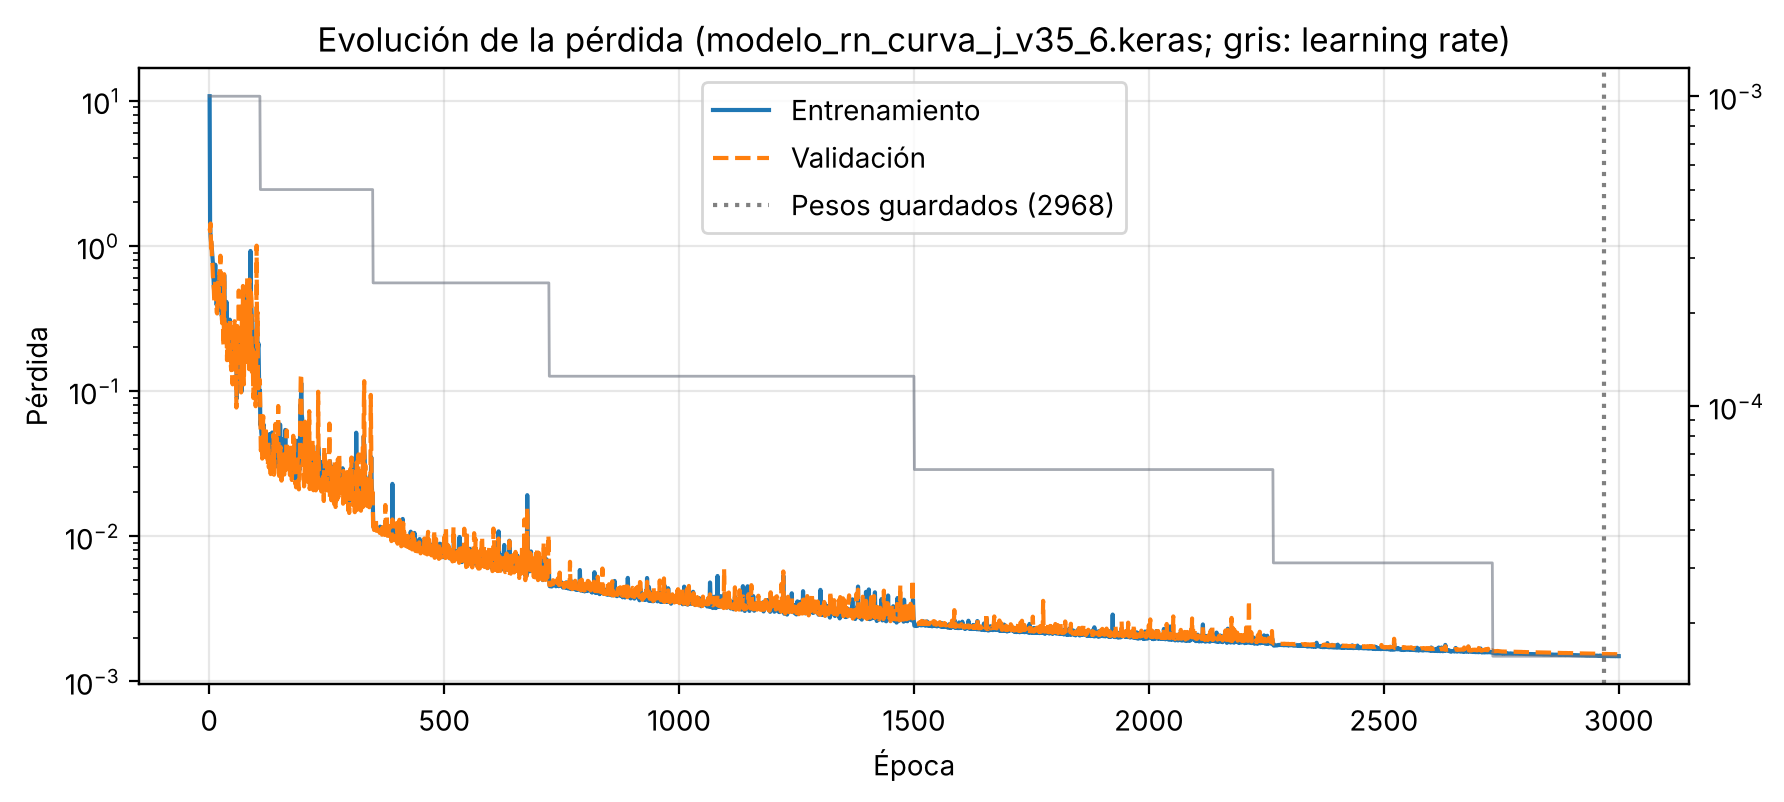

In [10]:
# CELDA 11: ENTRENAMIENTO (ENTRENAR = True) O CARGA DE LA RED ENTRENADA (False)
#   CONTINUAR = True (con la red cargada): sigue entrenando desde sus pesos con la tasa de aprendizaje reiniciada en LR_REINICIO;
#   solo guarda si baja la pérdida de validación. Poner de nuevo en False después de usarlo.
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import callbacks as cb
from tensorflow.keras.models import load_model

EPOCHS, BATCH_SIZE, MIN_DELTA = 3000, 256, 1e-5
CONTINUAR, EPOCAS_EXTRA, LR_REINICIO = False, 2000, 1e-4


def _callbacks():
    return [cb.TerminateOnNaN(), cb.EarlyStopping(patience=150, min_delta=MIN_DELTA, restore_best_weights=True),
            cb.ReduceLROnPlateau(factor=0.5, patience=50, min_delta=MIN_DELTA, min_lr=1e-6)]


if ENTRENAR:                                     # si el entrenamiento se corta, al volver a correr la celda sigue desde la última época
    import os, shutil
    t0, _resp, _log = time.time(), f"_respaldo_{VERSION}", f"_registro_{VERSION}.csv"
    model.fit(X_train, np.hstack([y_train, m_train]), validation_data=(X_val, np.hstack([y_val, m_val])), epochs=EPOCHS,
              batch_size=BATCH_SIZE, verbose=2, callbacks=_callbacks() + [cb.BackupAndRestore(_resp), cb.CSVLogger(_log, append=True)])
    hist = pd.read_csv(_log).drop_duplicates("epoch", keep="last").drop(columns="epoch")
    hist.index = pd.RangeIndex(1, len(hist) + 1, name="epoca")
    shutil.rmtree(_resp, ignore_errors=True)
    os.remove(_log)
    model.save(ARCHIVO_MODELO)
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump(dict(scaler_x=sx, scaler_y=sy, offset_log=OFFSET_LOG, c_lam_red=C_LAM_RED, nudos=NUDOS, bases=A_RED,
                         ensayos=list(ENSAYOS), version=VERSION), f)
    hist.to_csv(ARCHIVO_HISTORIAL)
    print(f"✅ Entrenada en {(time.time() - t0) / 60:.1f} min ({len(hist)} épocas) → {ARCHIVO_MODELO}, {ARCHIVO_SCALERS}")
else:
    model = load_model(ARCHIVO_MODELO, compile=False)
    hist = pd.read_csv(ARCHIVO_HISTORIAL, index_col="epoca")
    print(f"📦 Red cargada de '{ARCHIVO_MODELO}' (sin reentrenar; {len(hist)} épocas de entrenamiento)")
    if CONTINUAR:
        import tensorflow as tf
        Yv = np.hstack([y_val, m_val])
        model.compile(optimizer=tf.keras.optimizers.Adam(LR_REINICIO, clipnorm=1.0), loss=perdida, metrics=[mae])
        v0, n0, t0 = model.evaluate(X_val, Yv, batch_size=1024, verbose=0)[0], len(hist), time.time()
        h = model.fit(X_train, np.hstack([y_train, m_train]), validation_data=(X_val, Yv), initial_epoch=n0,
                      epochs=n0 + EPOCAS_EXTRA, batch_size=BATCH_SIZE, verbose=2, callbacks=_callbacks())
        v1 = model.evaluate(X_val, Yv, batch_size=1024, verbose=0)[0]
        print(f"   Continuación: val_loss {v0:.6f} → {v1:.6f} ({(v1 / v0 - 1) * 100:+.1f} %), {len(h.history['loss'])} épocas en "
              f"{(time.time() - t0) / 60:.1f} min")
        if v1 < v0:
            hist = pd.concat([hist, pd.DataFrame(h.history, index=pd.RangeIndex(n0 + 1, n0 + len(h.history["loss"]) + 1, name="epoca"))])
            model.save(ARCHIVO_MODELO)
            hist.to_csv(ARCHIVO_HISTORIAL)
            print(f"   ✅ Mejoró: guardada en {ARCHIVO_MODELO} ({len(hist)} épocas en total)")
        else:
            model = load_model(ARCHIVO_MODELO, compile=False)
            print("   ↩️ No mejoró: se mantiene la red anterior")

v = hist["val_loss"].to_numpy()
mejor, ep = np.inf, len(v)                       # época que restaura EarlyStopping (última mejora > MIN_DELTA)
for i, x_ in enumerate(v):
    if x_ + MIN_DELTA < mejor:
        mejor, ep = x_, i + 1
ep_conv = int(np.argmax(v <= v.min() * 1.01)) + 1
print(f"   Pesos de la época {ep}: val_loss {v[ep - 1]:.6f} | loss {hist['loss'].iloc[ep - 1]:.6f} | "
      f"convergencia práctica (≤ 1 % del mínimo) en la época {ep_conv}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(hist.index, hist["loss"], label="Entrenamiento")
ax.semilogy(hist.index, v, "--", label="Validación")
ax.axvline(ep, color="gray", ls=":", label=f"Pesos guardados ({ep})")
lr = next((c for c in ("learning_rate", "lr") if c in hist), None)
if lr:
    ax.twinx().semilogy(hist.index, hist[lr], color="#6b7280", lw=1, alpha=0.6)
ax.set(xlabel="Época", ylabel="Pérdida", title=f"Evolución de la pérdida ({ARCHIVO_MODELO}; gris: learning rate)")
ax.legend()
ax.grid(alpha=0.3)
plt.savefig(f"evolucion_perdida_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()


In [11]:
# CELDA 24: LÁMINAS ENTERAS — redondeo óptimo contra la curva de la arteria
#   «Redondeo minimax por programación lineal entera mixta (MILP, HiGHS)»: enteros z ≥ 0 de menor error punto a punto máximo,
#       min t  s.a.  −t ≤ y(λ_i) − Σ_j z_j·A_j(λ_i) ≤ t,  z_j entero ≥ 0   (HiGHS: ramificación y acotamiento con planos de corte).
#       Usa solo la curva y las bases (ni el MCO ni la red).
#   «Redondeo por mínimos cuadrados enteros (Schnorr–Euchner)»: enteros de menor E_rms contra la arteria. Como c_MCO es la proyección
#       de y sobre las bases, ||y − A·z||² = ||y − A·c_MCO||² + ||A·(z − c_MCO)||² (Pitágoras): se busca el entero más cercano a c_MCO
#       en la métrica AᵀA, por enumeración de Schnorr–Euchner sobre la factorización de Cholesky (búsqueda exacta).
#   «Redondeo simple»: cada lámina de la red al entero más cercano (referencia: no se recomienda).
import os
import sys
import time
import contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds

N_MUESTRA_ESPACIO = 2000                 # curvas del espacio de trabajo que se redondean (las 22 500 tardan ≈ 20 min)


@contextlib.contextmanager
def _silencio():
    sys.stdout.flush()
    fd, nul = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    os.dup2(nul, 1)
    try:
        yield
    finally:
        os.dup2(fd, 1); os.close(fd); os.close(nul)


def redondeo_minimax(y, B=None, z0=None, caja=None):
    """Redondeo minimax por MILP (HiGHS) en 500 puntos de λ. z0 y caja (± láminas alrededor de z0) solo acotan la búsqueda."""
    B = A if B is None else B
    Bs, ys = B[::2], np.asarray(y, float)[::2]
    m, n = Bs.shape
    lo, hi = np.zeros(n + 1), np.r_[np.full(n, np.inf), np.inf]
    if z0 is not None and caja is not None:
        lo[:n] = np.maximum(np.round(z0) - caja, 0)
        hi[:n] = np.round(z0) + caja
    with _silencio():
        r = milp(np.r_[np.zeros(n), 1.0], integrality=np.r_[np.ones(n), 0], bounds=Bounds(lo, hi),
                 constraints=LinearConstraint(np.vstack([np.c_[Bs, -np.ones(m)], np.c_[-Bs, -np.ones(m)]]), -np.inf, np.r_[ys, -ys]),
                 options=dict(time_limit=60))
    if r.x is None:                     # sin solución en 60 s (raro): se usa el de mínimos cuadrados enteros
        return redondeo_mce(np.linalg.lstsq(B, np.asarray(y, float), rcond=None)[0], B)
    return np.round(r.x[:n])


def redondeo_mce(c, B=None):
    """Redondeo por mínimos cuadrados enteros (Schnorr–Euchner): argmin_{z entero ≥ 0} (z − c)ᵀ BᵀB (z − c), con c = c_MCO."""
    B = A if B is None else B
    M = B.T @ B
    R = np.linalg.cholesky(M).T
    z0 = np.maximum(np.round(c), 0)
    mejor = [float((z0 - c) @ M @ (z0 - c)), z0.copy()]
    z = np.zeros(len(c))

    def nivel(k, parcial):
        s = c[k] - (R[k, k + 1:] @ (z[k + 1:] - c[k + 1:])) / R[k, k]
        radio = np.sqrt(max(mejor[0] - parcial, 0.0)) / abs(R[k, k])
        for v in sorted(range(max(0, int(np.ceil(s - radio))), int(np.floor(s + radio)) + 1), key=lambda v: abs(v - s)):
            z[k] = v
            p = parcial + (R[k, k] * (v - s)) ** 2
            if p < mejor[0]:
                if k == 0:
                    mejor[0], mejor[1] = p, z.copy()
                else:
                    nivel(k - 1, p)
    nivel(len(c) - 1, 0.0)
    return mejor[1]


def errores_curva(y, z, B=None):
    """(E_rms, e_máx) en % del rango de la curva y."""
    B = A if B is None else B
    r = np.asarray(y) - B @ z
    return 100 * np.sqrt(np.mean(r ** 2)) / np.ptp(y), 100 * np.abs(r).max() / np.ptp(y)


METODOS = ["MCO (sin redondear)", "Red neuronal (sin redondear)", "Redondeo simple (de la red)",
           "Mínimos cuadrados enteros (Schnorr–Euchner)", "Minimax (MILP, HiGHS)"]


In [12]:
# CELDA 17 (de V39, solo la parte de Fung: referencia)
# CELDA 17: GENERALIZACIÓN A UNA LEY NUNCA VISTA (Fung) Y CONTROL DE CLASE A LA ENTRADA
#   Fung: P = C + A·(exp(B·(λ − λ_min)) − 1), parámetros mezclados de los ajustes a sujetos de entrenamiento.
#   Control de clase: debe aceptar curvas J (Fung, sujetos) y rechazar sujetos de test modulados con una oscilación.
import numpy as np
from scipy.optimize import curve_fit

N_OOD, RUIDO_OOD = 300, 0.01
rng_ood = np.random.default_rng(2027)
fung = lambda x, a, b, c: c + a * (np.exp(b * (x - X_MIN)) - 1.0)
P_FUNG = np.array([curve_fit(fung, X, y, p0=(5.0, 20.0, max(float(y[0]), 0.01)), bounds=([1e-6, 1e-3, 0], [1e4, 200, 1e3]),
                             maxfev=20000)[0] for y in POB_Y[MASK_TRAIN]])
Y_fung = []
while len(Y_fung) < N_OOD:
    k = rng_ood.integers(2, 4)
    idx = rng_ood.choice(len(P_FUNG), size=k, replace=False)
    y = fung(X, *np.exp(rng_ood.dirichlet(np.ones(k)) @ np.log(P_FUNG[idx]) + rng_ood.normal(0.0, 0.10, size=3)))
    if y.min() > 0 and y.max() <= Y_TECHO:
        Y_fung.append(y)
Y_fung = np.array(Y_fung)
Y_fung_r = np.maximum(Y_fung + rng_ood.normal(0.0, RUIDO_OOD, size=Y_fung.shape) * np.abs(Y_fung), 0.0)
Mf_rn, Mf_opt = metricas(Y_fung_r, predecir(Y_fung_r) @ A.T), metricas(Y_fung_r, mco(Y_fung_r) @ A.T)
i = int(np.argmin(Mf_rn["R2"]))
print(f"🧪 Fung ({N_OOD} curvas, ruido 1 %, {np.mean((Y_fung < Y1) | (Y_fung > Y2)):.1%} de puntos fuera de y1–y2): "
      f"NRMSE red {Mf_rn['NRMSE'].mean():.3f}% | óptimo {Mf_opt['NRMSE'].mean():.3f}% | "
      f"exceso {(Mf_rn['NRMSE'].mean() / Mf_opt['NRMSE'].mean() - 1) * 100:+.1f}% | peor R² red {Mf_rn['R2'][i]:.5f} "
      f"(óptimo {Mf_opt['R2'][i]:.5f}) | MCO fabricable {np.mean((mco(Y_fung_r) >= 0).all(1)):.1%}")



🧪 Fung (300 curvas, ruido 1 %, 0.7% de puntos fuera de y1–y2): NRMSE red 0.807% | óptimo 0.772% | exceso +4.6% | peor R² red 0.99620 (óptimo 0.99944) | MCO fabricable 100.0%


In [13]:
# CELDA V49-1) LEYES EXTERNAS: σθθ [kPa] en función de su propio λθ
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar
LZ = 1.10   # estiramiento axial supuesto (Sommer y Holzapfel 2012 grafican σθθ(λθ) con λz = 1,05–1,15)

def sig_sommer(l, mu, k1, k2, phi, rho, lz=LZ):
    """Holzapfel et al. (2005) con dispersión, como en Sommer y Holzapfel (2012), ec. (21)–(24): σθθ − σrr (membrana)."""
    l = np.asarray(l, float); lr = 1 / (l * lz)
    I1 = l**2 + lr**2 + lz**2
    c2, s2 = np.cos(np.radians(phi))**2, np.sin(np.radians(phi))**2
    I4 = l**2 * c2 + lz**2 * s2
    E4 = np.maximum(I4 - 1, 0.0)                    # las fibras no trabajan a compresión
    Q = k2 * ((1 - rho) * (I1 - 3)**2 + rho * E4**2)
    eQ = np.exp(np.minimum(Q, 600))
    return 4 * ((l**2 - lr**2) * (mu / 4 + k1 * (1 - rho) * (I1 - 3) * eQ) + k1 * rho * l**2 * c2 * E4 * eQ)

def sig_hgo(l, c, k1, k2, beta, lz=LZ):
    """Holzapfel, Gasser y Ogden (2000), dos familias de fibras a ±β: σθθ − σrr."""
    l = np.asarray(l, float); lr = 1 / (l * lz)
    c2, s2 = np.cos(np.radians(beta))**2, np.sin(np.radians(beta))**2
    E4 = np.maximum(l**2 * c2 + lz**2 * s2 - 1, 0.0)
    return c * (l**2 - lr**2) + 4 * k1 * E4 * np.exp(np.minimum(k2 * E4**2, 600)) * l**2 * c2

def sig_mr(l, c1, D1, D2=2.0):
    """Mooney–Rivlin modificado, tracción uniaxial (Liu et al. 2012, ec. 4)."""
    l = np.asarray(l, float)
    return 2 * l * (l - l**-2) * (c1 + D1 * D2 * np.exp(D2 * (l**2 + 2 / l - 3)))

# Sommer y Holzapfel (2012), Tablas 1 y 2: (μ, k1 [kPa], k2, φ [°], ρ)
SOM = {
 "CCA pared": [("I l",70.2,99.9,26.4,11.5,1.0),("II l",46.0,32.7,12.1,19.9,1.0),("II r",38.7,9.7,19.6,18.9,0.5),
               ("IV l",34.2,15.5,199.2,17.1,0.8),("V l",2.2,14.2,64.5,30.3,1.0),("V r",28.2,8.0,15.1,10.5,0.6),
               ("VI l",82.1,43.6,120.1,24.2,0.5),("VI r",54.8,2.9,20.3,31.2,1.0),("VII r",73.1,5.1,116.8,14.0,0.7),
               ("VIII r",54.8,13.0,91.5,26.1,0.9),("IX r",4.9,68.2,71.8,20.9,0.6)],
 "CCA adventicia": [("II l",0.0,875.2,146.3,41.2,0.8),("II r",70.5,61.2,32.8,15.9,0.9),("V l",95.4,8.5,328.3,38.2,1.0),
               ("V r",60.0,1.6,41.5,23.9,0.9),("VI l",34.7,52.2,88.9,26.6,0.7),("VI r",61.6,28.7,85.8,21.8,0.6),
               ("VIII r",95.1,238.8,45.3,42.9,0.9)],
 "CCA media-íntima": [("II l",134.6,10.3,18.8,8.8,0.7),("IV l",106.8,26.5,23.0,3.5,0.9),("V r",128.9,25.9,21.5,6.8,0.7),
               ("VI r",118.9,36.1,2.8,8.5,1.0)],
 "ICA pared": [("III l",43.8,93.6,79.6,17.2,0.7),("IV l",23.7,7.5,12.2,11.6,0.8),("V r",24.6,13.4,29.9,7.3,0.6),
               ("VI l",22.9,87.8,109.6,19.3,0.7),("VI r",3.8,1.2,42.9,19.8,0.7),("VII r",12.4,93.4,96.9,21.8,0.7),
               ("VIII r",35.7,1.3,63.1,34.6,0.9),("IX r",31.8,39.8,80.9,21.3,0.9),("X r",25.6,20.4,68.7,26.8,0.7),
               ("XI r",7.4,4.5,45.7,22.4,0.8)],
 "ICA adventicia": [("VI r",0.0,15.9,75.5,40.7,1.0),("VII r",0.3,51.5,38.9,20.4,0.7),("VIII r",11.3,475.3,63.2,41.6,0.9),
               ("IX l",3.0,43.2,44.9,29.8,0.8),("X r",5.7,17.0,76.7,41.3,1.0),("XI r",149.5,69.9,304.6,16.8,1.0)],
 "ICA media-íntima": [("IX r",0.7,17.0,7.6,12.4,0.6),("X r",36.2,14.2,26.6,10.2,0.8),("XI r",15.8,32.7,17.8,6.7,0.9)],
}
# Holzapfel, Gasser y Ogden (2000): carótida de conejo (c, k1 [kPa], k2, β [°])
HGO = {"conejo media": (3.0, 2.3632, 0.8393, 29.0), "conejo adventicia": (0.3, 0.5620, 0.7112, 62.0)}
# Liu et al. (2012), Tabla 1: Max-Cir, Min-Cir [cm], c1, D1 [kPa], contracción circunferencial S
LIU = [("P1",2.30,1.99,18.00,7.05,0.185),("P2",2.24,1.95,12.90,5.05,0.167),("P3",3.37,3.12,90.00,35.22,0.060),
       ("P4",1.76,1.60,27.00,10.57,0.126),("P5",1.51,1.38,18.75,7.34,0.111),("P6",1.91,1.73,16.90,6.62,0.145),
       ("P7",1.84,1.74,40.20,15.77,0.062),("P8",2.69,2.42,35.00,13.70,0.070),("P9",2.84,2.53,38.00,14.94,0.080),
       ("P10",1.88,1.70,41.50,16.27,0.078),("P11",2.04,1.74,8.60,3.37,0.326),("P12",1.32,1.22,13.00,5.10,0.10)]
# Kamenskiy et al. (2012), in vivo: σ diástole–sístole [kPa], E diástole, E sístole [MPa], diámetro interno sístole/diástole [mm]
K_SIG = [[(37,137),(22,78),(35,113)],[(17,49),(16,45),(21,52)],[(17,35),(15,29),(13,25)],[(23,72),(18,47),(18,47)],
         [(31,75),(20,67),(21,51)],[(19,56),(21,57),(18,44)],[(22,51),(29,67),(33,86)],[(33,77),(37,85),(34,89)],
         [(20,52),(23,71),(43,94)],[(17,48),(14,33),(24,64)],[(26,52),(16,28),(30,60)],[(22,60),(31,84),(34,81)],
         [(16,45),(17,39),(33,76)],[(30,67),(23,52),(29,61)],[(31,57),(31,55),(28,50)],[(33,78),(24,67),(31,81)]]
K_ED = [[.41,.16,.78],[.19,.09,.94],[.15,.19,.16],[.45,.26,.42],[.67,.19,.39],[.16,.16,.21],[.88,.95,.91],[.47,.78,.53],
        [.20,.30,.76],[.22,1.29,.95],[.61,.66,.85],[.23,.66,1.06],[.17,.35,.79],[.31,.63,.65],[.47,.71,.32],[.88,.45,1.14]]
K_ES = [[.63,1.50,2.38],[.88,.89,1.69],[.17,.25,.40],[.83,1.11,1.43],[.69,.33,.39],[.85,.59,.65],[6.25,2.22,2.00],
        [2.68,1.60,1.90],[.34,.52,2.43],[.83,1.30,.96],[1.06,1.32,.86],[.55,1.17,1.60],[.17,1.09,1.89],[.83,1.22,2.08],
        [.48,1.67,2.25],[6.82,1.41,1.19]]
K_DS = [[8.98,4.59,5.15],[6.26,5.54,6.17],[8.64,5.67,5.48],[12.45,7.88,9.13],[13.89,4.36,5.55],[6.27,4.32,3.53],
        [7.79,5.78,5.49],[7.39,6.35,5.83],[7.68,4.69,4.44],[7.89,3.80,5.94],[8.23,4.78,8.02],[6.48,3.99,5.78],
        [7.34,4.12,6.64],[9.13,5.40,5.31],[8.73,5.09,7.43],[7.04,3.39,4.46]]
K_DD = [[7.56,3.90,4.78],[5.70,4.80,6.01],[7.85,5.31,5.24],[11.52,7.46,8.79],[13.07,3.65,5.17],[5.58,3.67,3.26],
        [7.65,5.62,5.26],[7.07,6.10,5.45],[6.89,4.23,4.27],[7.15,3.74,5.72],[7.93,4.72,7.79],[5.75,3.75,5.57],
        [6.18,3.92,6.40],[8.41,5.21,5.16],[8.28,4.98,7.19],[6.86,3.16,4.29]]

def curva_kamenskiy(sd, ss, Ed, Es, es):
    """σ(ε) = σd + α(e^{βε} − 1) en ε ∈ [0, εs] con σ(εs) = σs exacto y β que mejor reproduce (en logaritmo) las pendientes
    medidas en diástole (Ed) y sístole (Es). Ed > Es da β < 0 (curva cóncava: no es J)."""
    def f(b):
        a = (ss - sd) / (np.expm1(b * es) / b if abs(b) > 1e-9 else es)
        return np.log(a / (Ed * 1e3))**2 + np.log(a * np.exp(b * es) / (Es * 1e3))**2
    b = minimize_scalar(f, bounds=(-60, 200), method='bounded').x
    a = (ss - sd) / (np.expm1(b * es) / b)
    return (lambda e: sd + a / b * np.expm1(b * np.asarray(e))), b


In [14]:
# CELDA V54-2) VENTANA DIÁSTOLE–SÍSTOLE PARA TODAS LAS CURVAS (un solo escalamiento; σ sin tocar)
#   Cada curva se lleva a [X_MIN, X_MAX] con un cambio afín de λ: el estiramiento diastólico va a X_MIN y el sistólico a X_MAX.
#   • In vivo (Liu, Kamenskiy): la ventana MEDIDA (protocolo M).
#   • Ex vivo (Sommer y Holzapfel 2012): la ventana CALCULADA entre 60 y 200 mmHg (protocolo P), con la geometría
#     sin carga publicada y el equilibrio de pared delgada que usan Sommer et al. (2010), ec. 1–2:
#        σθθ = p·(r/h − 1),  r = R·λθ (radio externo),  [R² − (R − H)²] = [r² − (r − h)²]·λz  (incompresible).
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar
P_DIA, P_SIS = 60 * 0.133322, 200 * 0.133322          # kPa: la misma ventana de presión que el nivel tubo (60 a 200 mmHg)
# Geometría sin carga: Sommer et al. (2010), Tabla 2 (medias por arteria y capa): radio externo R y espesor H [mm]
GEO_SOM = {"CCA pared": (4.15, 1.17), "CCA adventicia": (4.00, 0.47), "CCA media-íntima": (3.61, 0.70),
           "ICA pared": (2.67, 0.86), "ICA adventicia": (2.51, 0.33), "ICA media-íntima": (2.15, 0.53)}
# Holzapfel, Gasser y Ogden (2000), carótida de conejo: radio interno 0,71 mm, media 0,26 mm, adventicia 0,13 mm
GEO_HGO = {"conejo media": (0.71 + 0.26, 0.26), "conejo adventicia": (0.71 + 0.26 + 0.13, 0.13)}


def a_dominio(f, la, lb):
    return f(la + (X - X_MIN) / (X_MAX - X_MIN) * (lb - la))


def presion(f, R, H, l, lz=LZ):
    """Presión transmural [kPa] que equilibra la tensión f(λθ) en un tubo de pared delgada (Sommer et al. 2010, ec. 1–2)."""
    r = R * np.asarray(l, float)
    h = r - np.sqrt(np.maximum(r**2 - (R**2 - (R - H)**2) / lz, 0.0))
    return f(l) / (r / h - 1)


def ventana_presion(f, R, H, pa=P_DIA, pb=P_SIS, l0=1.0, l1=4.0):
    g = np.linspace(l0, l1, 30001); p = presion(f, R, H, g)
    if p[-1] < pb or not np.all(np.diff(p) > -1e-9):
        return None
    ia, ib = np.argmax(p >= pa), np.argmax(p >= pb)
    if ia == 0:                                         # sin carga ya soporta la presión diastólica: no hay tramo diastólico
        return None
    la = brentq(lambda l: presion(f, R, H, l) - pa, g[ia - 1], g[ia])
    lb = brentq(lambda l: presion(f, R, H, l) - pb, g[ib - 1], g[ib])
    return la, lb


filas, CURV = [], []
def agrega(fuente, grupo, nombre, protocolo, ventana, y, extra=None):
    CURV.append(y); filas.append(dict(fuente=fuente, grupo=grupo, curva=nombre, protocolo=protocolo, ventana=ventana, **(extra or {})))

sin_ventana = []
for grupo, lista in SOM.items():
    R, H = GEO_SOM[grupo]
    for (nm, mu, k1, k2, phi, rho) in lista:
        f = lambda l, p=(mu, k1, k2, phi, rho): sig_sommer(l, *p)
        w = ventana_presion(f, R, H)
        if w is None:
            sin_ventana.append(f"{grupo} {nm}"); continue
        agrega("Sommer y Holzapfel 2012", grupo, nm, "P", "60–200 mmHg", a_dominio(f, *w), dict(la=w[0], lb=w[1]))
# Holzapfel et al. (2000), conejo: se excluye. Como capas aisladas con la geometría del conejo, a 60–200 mmHg dan tensiones de
# 900 a 3300 kPa, muy lejos de cualquier carótida humana (ver V54, prueba con conejo).
for (nm, mx, mn, c1, D1, Sh) in LIU:
    f = lambda l, p=(c1, D1): sig_mr(l, *p)
    ld = 1 / (1 - Sh); ls = ld * mx / mn
    agrega("Liu et al. 2012", "carótida con placa", nm, "M", "medida", a_dominio(f, ld, ls), dict(la=ld, lb=ls))
ART = ["CCA", "ECA", "ICA"]
for i in range(16):
    for j in range(3):
        sd, ss = K_SIG[i][j]; es = K_DS[i][j] / K_DD[i][j] - 1
        f, b = curva_kamenskiy(sd, ss, K_ED[i][j], K_ES[i][j], es)
        agrega("Kamenskiy et al. 2012", ART[j], f"pac. {i + 1}", "M", "medida", f((X - X_MIN) / (X_MAX - X_MIN) * es),
               dict(la=1.0, lb=1 + es, beta=b))
Y_EXT = np.array(CURV)
T = pd.DataFrame(filas)
print(f"{len(T)} curvas externas:", T.groupby(["fuente", "protocolo"]).size().to_dict())
print("Sin ventana 60–200 mmHg (la presión no llega o no crece):", sin_ventana or "ninguna")
_P = T.protocolo == "P"
print("Ventanas P: λ diastólico", T.loc[_P, "la"].describe().round(3).to_dict(), "| λ sistólico", T.loc[_P, "lb"].describe().round(3).to_dict())
print("Tensiones [kPa] en diástole y sístole por protocolo:")
print(pd.DataFrame({"protocolo": T.protocolo, "σ_d": Y_EXT[:, 0], "σ_s": Y_EXT[:, -1]}).groupby("protocolo").describe().round(1).T.to_string())


98 curvas externas: {('Kamenskiy et al. 2012', 'M'): 48, ('Liu et al. 2012', 'M'): 12, ('Sommer y Holzapfel 2012', 'P'): 38}
Sin ventana 60–200 mmHg (la presión no llega o no crece): ['CCA adventicia II l', 'CCA adventicia VIII r', 'ICA adventicia VIII r']
Ventanas P: λ diastólico {'count': 38.0, 'mean': 1.062, 'std': 0.042, 'min': 1.009, '25%': 1.029, '50%': 1.057, '75%': 1.084, 'max': 1.165} | λ sistólico {'count': 38.0, 'mean': 1.113, 'std': 0.053, 'min': 1.028, '25%': 1.071, '50%': 1.109, '75%': 1.138, 'max': 1.238}
Tensiones [kPa] en diástole y sístole por protocolo:
protocolo      M      P
σ_d count   60.0   38.0
    mean    28.0   41.2
    std     12.3   20.9
    min     13.0   20.6
    25%     19.8   26.5
    50%     27.1   31.3
    75%     33.0   57.1
    max     88.0   92.0
σ_s count   60.0   38.0
    mean    72.1  154.4
    std     49.0   72.7
    min     25.0   76.4
    25%     50.8   98.2
    50%     62.5  130.4
    75%     81.0  207.7
    max    389.0  325.1


In [15]:
# CELDA V49-3) EVALUACIÓN: MCO, red, minimax entero, control de clase, forma J y banda y1–y2
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar
t0 = time.time()
C_M = mco(Y_EXT); B_M = C_M @ A.T
C_R = predecir(Y_EXT); B_R = C_R @ A.T
rng = np.random.default_rng(49)
Y_RU = np.maximum(Y_EXT + rng.normal(0, 0.01, Y_EXT.shape) * np.abs(Y_EXT), 0)
C_RR = predecir(Y_RU)
eM, nM = err_pct(Y_EXT, B_M); eR, nR = err_pct(Y_EXT, B_R); eRR, nRR = err_pct(Y_EXT, C_RR @ A.T)
_, nMR = err_pct(Y_RU, mco(Y_RU) @ A.T); _, nRR_in = err_pct(Y_RU, C_RR @ A.T)
Z = np.array([redondeo_minimax(y) for y in Y_EXT]); eZ, nZ = err_pct(Y_EXT, Z @ A.T)
Z2 = np.array([redondeo_minimax(y, B=A / 2) for y in Y_EXT]); eZ2, _ = err_pct(Y_EXT, Z2 @ (A / 2).T)   # sensibilidad: láminas de la mitad de espesor
forma = np.array([diagnostico_forma(y) for y in Y_EXT])
T["J"] = forma.all(1)
T["dist_clase_%"] = [distancia_clase(y) for y in Y_EXT]
T["acepta"] = T["dist_clase_%"] <= TOL_CLASE_NRMSE
T["fuera_banda_%"] = ((Y_EXT < Y1) | (Y_EXT > Y2)).mean(1) * 100
T["sigma_min"], T["sigma_max"] = Y_EXT[:, 0], Y_EXT[:, -1]
T["MCO_emax_%"], T["MCO_nrmse_%"], T["MCO_fabricable"] = eM, nM, (C_M >= -1e-9).all(1)
T["red_emax_%"], T["red_nrmse_%"], T["exceso_red_%"] = eR, nR, (nR / nM - 1) * 100
T["red_ruido_emax_%"], T["exceso_red_ruido_%"] = eRR, (nRR_in / nMR - 1) * 100
T["ent_emax_%"], T["ent_cumple_3%"], T["laminas_ent"] = eZ, eZ <= ERROR_MAX_PCT, Z.sum(1)
T["MCO_cumple_3%"] = eM <= ERROR_MAX_PCT
T["rango_kPa"] = np.ptp(Y_EXT, axis=1); T["ent_emax_kPa"] = eZ / 100 * T["rango_kPa"]
T["ent_mitad_emax_%"] = eZ2; T["ent_mitad_cumple_3%"] = eZ2 <= ERROR_MAX_PCT
T["en_banda"] = T["fuera_banda_%"] <= 1.0
T["red_cumple_3%"] = eR <= ERROR_MAX_PCT
for j in range(N_BASES):
    T[f"z{j + 1}"] = Z[:, j]
print(f"Evaluación en {time.time() - t0:.0f} s")
T.to_csv(f"v54_curvas_externas_{N_BASES}.csv", index=False)
np.save(f"v54_Y_{N_BASES}.npy", Y_EXT)

# Referencias: sujetos de test de Masson y Fung (como en V39)
_, nMf = err_pct(Y_fung_r, mco(Y_fung_r) @ A.T); _, nRf = err_pct(Y_fung_r, predecir(Y_fung_r) @ A.T)
YT = POB_Y[MASK_TEST]; _, nMt = err_pct(YT, mco(YT) @ A.T); _, nRt = err_pct(YT, predecir(YT) @ A.T)
ref = dict(fung_exceso=float((nRf.mean() / nMf.mean() - 1) * 100), test_exceso=float((nRt.mean() / nMt.mean() - 1) * 100))

def resumen(D):
    J = D[D.J & D.acepta]
    return pd.Series({"n": len(D), "J": int(D.J.sum()), "aceptadas": int(D.acepta.sum()),
        "fuera banda % (med)": D["fuera_banda_%"].median(),
        "MCO emax med": J["MCO_emax_%"].median(), "MCO emax peor": J["MCO_emax_%"].max(),
        "MCO ≤3%": f'{int(J["MCO_cumple_3%"].sum())}/{len(J)}', "MCO fabricable": f'{int(J["MCO_fabricable"].sum())}/{len(J)}',
        "exceso red %": (J["red_nrmse_%"].mean() / J["MCO_nrmse_%"].mean() - 1) * 100 if len(J) else np.nan,
        "exceso red ruido %": J["exceso_red_ruido_%"].median() if len(J) else np.nan,
        "red emax med": J["red_emax_%"].median(), "red emax peor": J["red_emax_%"].max(),
        "red ≤3%": f'{int(J["red_cumple_3%"].sum())}/{len(J)}',
        "red ≤3% en banda": f'{int((J["red_cumple_3%"] & J.en_banda).sum())}/{int(J.en_banda.sum())}',
        "rango kPa med": J["rango_kPa"].median(), "entero emax kPa peor": J["ent_emax_kPa"].max(),
        "entero mitad ≤3%": f'{int(J["ent_mitad_cumple_3%"].sum())}/{len(J)}',
        "entero emax med": J["ent_emax_%"].median(), "entero emax peor": J["ent_emax_%"].max(),
        "entero ≤3%": f'{int(J["ent_cumple_3%"].sum())}/{len(J)}'})
R = T.groupby(["fuente", "grupo", "protocolo"]).apply(resumen)
RT = T.groupby(["fuente", "protocolo"]).apply(resumen)
R.to_csv(f"v54_resumen_grupos_{N_BASES}.csv"); RT.to_csv(f"v54_resumen_fuentes_{N_BASES}.csv")
pd.set_option("display.width", 250)
print(RT.round(2).to_string()); print(R.round(2).to_string())
print("Referencias V39 (exceso de la red sobre el MCO en NRMSE medio):", {k: round(v, 1) for k, v in ref.items()})
# Rechazadas por el control de clase: ¿son las no-J?
print("Cruce J × aceptada:\n", pd.crosstab(T.J, T.acepta))
print("Rechazadas: error de la red", T.loc[~T.acepta, "red_emax_%"].round(1).tolist(), "| ventana con λa en el borde (σ(1) > σ pedida):",
      int((~T.acepta & (T.la <= 1.0001) & (T.protocolo == "P")).sum()))
print("Aceptadas: red ≤3 % dentro de la banda y1–y2:", int((T.acepta & T.en_banda & T["red_cumple_3%"]).sum()), "/", int((T.acepta & T.en_banda).sum()),
      "| fuera de la banda:", int((T.acepta & ~T.en_banda & T["red_cumple_3%"]).sum()), "/", int((T.acepta & ~T.en_banda).sum()))
print("Kamenskiy con β<0 (cóncavas):", int((T.beta < 0).sum()), "| Es<Ed:",
      sum(K_ES[i][j] < K_ED[i][j] for i in range(16) for j in range(3)))
pd.Series(ref).to_csv(f"v54_referencias_{N_BASES}.csv")


Evaluación en 13 s


                                    n   J  aceptadas  fuera banda % (med)  MCO emax med  MCO emax peor MCO ≤3% MCO fabricable  exceso red %  exceso red ruido %  red emax med  red emax peor red ≤3% red ≤3% en banda  rango kPa med  entero emax kPa peor entero mitad ≤3%  entero emax med  entero emax peor entero ≤3%
fuente                  protocolo                                                                                                                                                                                                                                                                                        
Kamenskiy et al. 2012   M          48  48         45                  0.0          0.84           1.28   45/45          40/45         96.02                3.37          0.98           4.05   44/45            27/27          37.00                  1.71            42/45             2.38              8.69      30/45
Liu et al. 2012         M          12  12         12      

In [16]:
# CELDA V49-4) FIGURAS (tensión en ordenadas)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar
cols = {"Sommer y Holzapfel 2012": "#1f77b4", "Holzapfel et al. 2000": "#9467bd", "Liu et al. 2012": "#2ca02c",
        "Kamenskiy et al. 2012": "#d62728"}
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, prot in zip(axs, ["P", "M"]):
    banda(ax)
    for i in np.where(T.protocolo == prot)[0]:
        ax.plot(X, Y_EXT[i], color=cols[T.fuente[i]], lw=0.7, alpha=0.6, ls="-" if T.acepta[i] else ":")
    for f_, c_ in cols.items():
        if ((T.fuente == f_) & (T.protocolo == prot)).any():
            ax.plot([], [], color=c_, label=f_)
    ax.plot([], [], "k:", label="rechazada por el control de clase")
    ax.set(xlabel=ETQ_X, title=("P: ventana 60–200 mmHg calculada (ex vivo)" if prot == "P"
                                else "M: ventana diástole–sístole medida in vivo"))
    ax.grid(alpha=.3, ls=":"); ax.legend(fontsize=8, loc="upper left")
axs[0].set_ylabel(ETQ_Y)
plt.tight_layout(); plt.savefig(f"v54_curvas_externas_{N_BASES}.png", dpi=200); plt.close()

# Peores casos aceptados: curva, MCO, red y entero
ok = np.where(T.J & T.acepta)[0]
peores = ok[np.argsort(-T["ent_emax_%"].values[ok])[:6]]
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, i in zip(axs.flat, peores):
    banda(ax)
    ax.plot(X, Y_EXT[i], "k-", lw=2, label="Curva externa")
    ax.plot(X, B_M[i], "b:", lw=1.6, label=f"MCO ({eM[i]:.2f} %)")
    ax.plot(X, B_R[i], "r--", lw=1.4, label=f"Red ({eR[i]:.2f} %)")
    ax.plot(X, Z[i] @ A.T, "g-.", lw=1.4, label=f"Entero minimax ({eZ[i]:.2f} %)")
    ax.set_title(f"{T.fuente[i]} · {T.grupo[i]} {T.curva[i]} ({T.protocolo[i]}, {T.ventana[i]})", fontsize=8)
    ax.set(xlabel=ETQ_X, ylabel=ETQ_Y); ax.grid(alpha=.3, ls=":"); ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig(f"v54_peores_casos_{N_BASES}.png", dpi=200); plt.close()

# Error del entero minimax por fuente (cajas), con las referencias de los 41 sujetos de V39
fig, ax = plt.subplots(figsize=(10, 4.5))
grupos = [(f_, p_) for f_ in cols for p_ in ("P", "M") if ((T.fuente == f_) & (T.protocolo == p_) & T.J & T.acepta).any()]
ax.boxplot([T.loc[(T.fuente == f_) & (T.protocolo == p_) & T.J & T.acepta, "ent_emax_%"] for f_, p_ in grupos],
           tick_labels=[f"{f_.split(' ')[0]}\n{p_}" for f_, p_ in grupos])
ax.axhline(ERROR_MAX_PCT, color="r", ls="--", label="criterio 3 %")
ax.set(ylabel="Error punto a punto máximo, láminas enteras [% del rango]")
ax.grid(alpha=.3, ls=":"); ax.legend()
plt.tight_layout(); plt.savefig(f"v54_error_entero_{N_BASES}.png", dpi=200); plt.close()
print("✅ V49 terminado")


✅ V49 terminado


In [17]:
# CELDA V54-5) ARREGLOS PARA LAS FIGURAS Y TABLAS DEL ARTÍCULO
np.savez(f'v54_arreglos_{N_BASES}.npz', X=X, Y1=Y1, Y2=Y2, Y_EXT=Y_EXT, A=A, C_M=C_M, Z=Z, B_M=B_M, B_R=B_R)
print('✅ V54 terminado')


✅ V54 terminado
